

**Goals:** filter detector data against a waveform template; find GW150914; understand the role of a PSD; compute Allen $\chi^2$ statistic and the reweighted SNR.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from pycbc import frame
from pycbc.catalog import Merger
from pycbc.types import TimeSeries
from pycbc.frame import read_frame
from pycbc.filter import highpass, resample_to_delta_t
from pycbc.psd import welch, interpolate, inverse_spectrum_truncation
from pycbc.waveform import get_td_waveform
from pycbc.filter import matched_filter
from pycbc.vetoes import power_chisq
from pycbc.events.ranking import newsnr

/home/abhishek.sharma/miniconda3/envs/gw-env/lib/python3.11/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


In [2]:
GPS = 1126259462.4  # GW150914 geocentric GPS time
SAMPLING_FREQ = 2048
DURATION = 64
DATA_DIR = Path('../data')

def load_detector(ifo='H1'):

    """Read locally cached, unfiltered GWOSC strain and prepare it for analysis."""
    
    path = DATA_DIR / f'GW150914_{ifo}_4096Hz_64s.gwf'
    channel = f'{ifo}:GWOSC-4KHZ_R1_STRAIN'
    
    if not path.exists():
        raise FileNotFoundError(f'{path} not found. From the repository root run: python download_data.py')
    
    raw = read_frame(str(path), channel)
    highpassed = resample_to_delta_t(highpass(raw, 15.0), 1.0 / SAMPLING_FREQ)
    conditioned = highpassed.crop(2, 2)
    
    return conditioned

def estimate_psd(data, f_low=20):
    seg = 4 * SAMPLING_FREQ
    psd = welch(data, seg_len=seg, seg_stride=seg//2)

    # We need to interpolate it to match the resolution of data.
    psd = interpolate(psd, data.delta_f)

    # 1/PSD will now act as a filter with an effective length of 4 seconds
    # Since the data has been highpassed above `f_low` Hz, and will have low values
    # below this we need to inform the function to not include frequencies
    # below this frequency.
    psd = inverse_spectrum_truncation(psd, int(4*SAMPLING_FREQ),
                                       low_frequency_cutoff=f_low)
    return psd

def waveform_template(data, m1=36, m2=29, f_low=20):
    hp, hc = get_td_waveform(approximant='IMRPhenomD', mass1=m1, mass2=m2,
                             delta_t=data.delta_t, f_lower=f_low,
                             distance=410)
    # Template ending at index 0, padded to length of the data.
    hp.resize(len(data))
    return hp

plt.rcParams.update({'figure.figsize':(11,4),'font.size':11})

In [3]:
# Load H1 and L1 strain data
h1 = load_detector('H1')
l1 = load_detector('L1')

# Print data information
for ifo, strain in [('H1', h1), ('L1', l1)]:
    print(f'{ifo}:')
    print('  Duration (s):', len(strain) * strain.delta_t)
    print('  Sampling rate (Hz):', strain.sample_rate)
    print('  Start GPS:', strain.start_time)

H1:
  Duration (s): 60.0
  Sampling rate (Hz): 2048.0
  Start GPS: 1126259432
L1:
  Duration (s): 60.0
  Sampling rate (Hz): 2048.0
  Start GPS: 1126259432


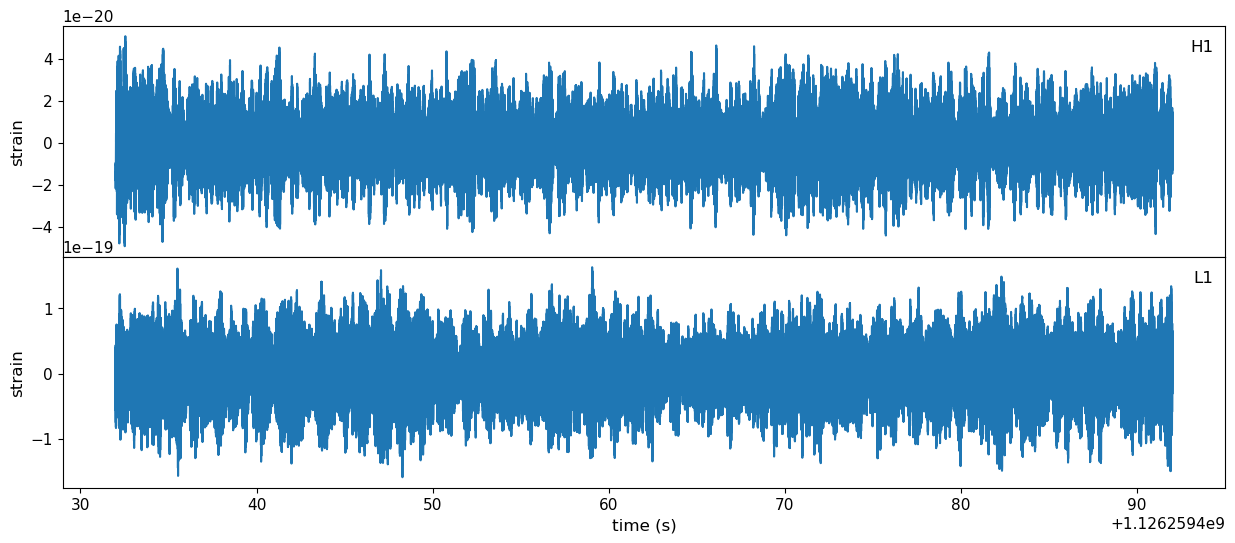

In [4]:
ifos = ["H1", "L1"]
strain = {}
strain['H1'] = h1
strain['L1'] = l1

# Plotting whitened data and signal in three detectors.
fig, ax = plt.subplots(2, 1, sharex = True, figsize = (15, 6))
fig.subplots_adjust(hspace = 0)

for i, ifo in enumerate(ifos):
    ax[i].plot(strain[ifo].sample_times, strain[ifo])
    ax[i].set_ylabel('strain', fontsize = 12)
    ax[i].set_title(ifo, x = 0.99, y = 0.95, pad = -10, fontsize = 12, loc='right')
    # ax[i].set_xlim(tTrigger - 0.4, tTrigger + 0.05)
    if i == 1:
        ax[i].set_xlabel('time (s)', fontsize = 12)

plt.show()

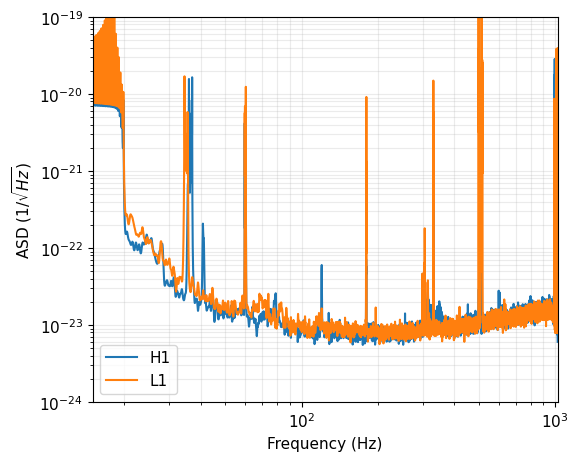

Frequency bin width (Hz): 0.016666666666666666


In [5]:
psds = {}

for ifo in ["H1", "L1"]:
    
    psds[ifo] = estimate_psd(strain[ifo])

fig,ax=plt.subplots(figsize = (6, 5))
ax.loglog(psds['H1'].sample_frequencies, np.sqrt(psds["H1"]), label = "H1")
ax.loglog(psds['L1'].sample_frequencies, np.sqrt(psds["L1"]), label = "L1")
ax.set(xlabel='Frequency (Hz)',ylabel=r'ASD ($1/\sqrt{Hz}$)', xlim=[15, 1024], ylim = [1e-24, 1e-19])
ax.grid(True,which='both',alpha=.25)
plt.legend()
plt.show()
print('Frequency bin width (Hz):',psds["H1"].delta_f)

## Matched-filter SNR

The noise-weighted inner product between two time series, $a(t)$ and $b(t)$, is defined as

$$
(a|b)
=
4\,\mathrm{Re}
\int_0^\infty
\frac{\tilde a(f)\,\tilde b^*(f)}
{S_n(f)}
\,df,
$$

where:

- $\tilde a(f)$ and $\tilde b(f)$ are the Fourier transforms of $a(t)$ and $b(t)$,
- $S_n(f)$ is the one-sided power spectral density (PSD) of the detector noise,
- and $^*$ denotes complex conjugation.

Given detector data $s(t)$ and a template waveform $h(t)$, the matched-filter output as a function of time lag is

$$
\rho(t)
=
4
\int_0^\infty
\frac{\tilde s(f)\,\tilde h^*(f)}
{S_n(f)}
e^{2\pi i f t}
\,df.
$$

The quantity $\rho(t)$ is called the **matched-filter signal-to-noise ratio (SNR) time series**. A significant peak in $|\rho(t)|$ indicates the presence of a signal in the data whose morphology is consistent with the template waveform. $h(t)$.

### Generate a template waveform

In this case we "know" what the signal parameters are. In a real search we would grid over the parameters and calculate the SNR time series for each one.

We will assume equal masses, and non-rotating black holes which is within the posterior probability of GW150914.

In [6]:
m1, m2 = 36, 36
hp, hc = get_td_waveform(approximant="SEOBNRv4",
                     mass1=m1,
                     mass2=m2,
                     delta_t=strain['H1'].delta_t,
                     f_lower=20)

# Resize the vector to match our data
hp.resize(len(strain['H1']))

The waveform begins at the start of the vector, so if we want the SNR time series to correspond to the approximate merger location, we need to shift the data so that the merger is approximately at the first bin of the data.

The `cyclic_time_shift` method shifts the timeseries by a given amount of time.
It treats the data as if it were on a ring so points shifted off the end of the series reappear at the start. 

Note that time stamps are *not* in general affected (as the start time of the full array is shifted), but the index of each point in the vector is.

By convention, waveforms returned from `get_td_waveform` have their merger stamped with time zero, so we can use the start time to shift the merger into position.

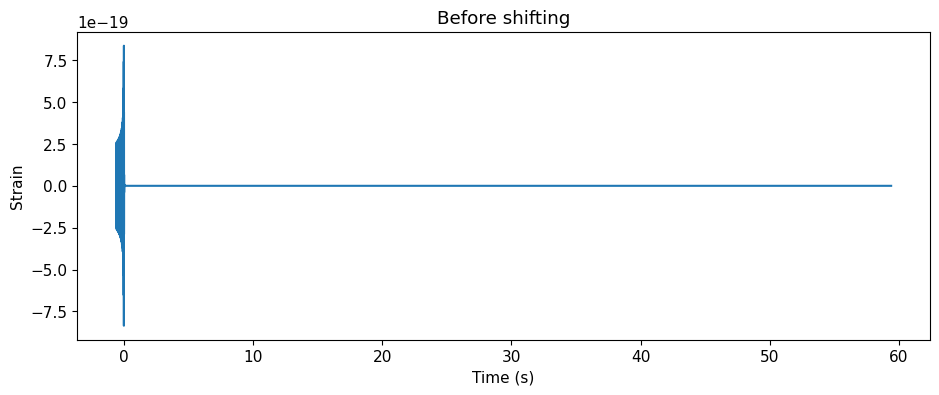

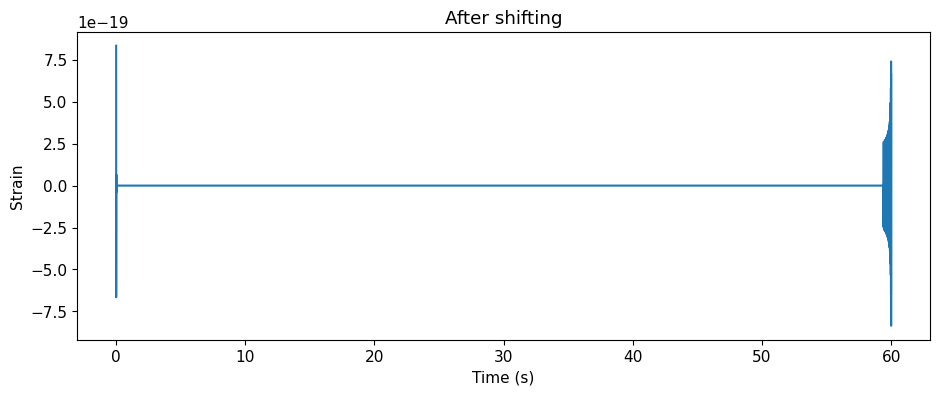

In [7]:
# Let's plot the signal before and after shifting

plt.figure()
plt.title('Before shifting')
plt.plot(hp.sample_times, hp)
plt.xlabel('Time (s)')
plt.ylabel('Strain')

template = hp.cyclic_time_shift(hp.start_time)

plt.figure()
plt.title('After shifting')
plt.plot(template.sample_times, template)
plt.xlabel('Time (s)')
plt.ylabel('Strain')
plt.show()

In [8]:


snr = {}
for ifo in ifos:
    snr[ifo] = matched_filter(template, strain[ifo],
                             psd=psds[ifo], low_frequency_cutoff=20)

    # Remove time corrupted by the template filter and the psd filter
    # We remove 4 seconds at the beginning and end for the PSD filtering
    # And we remove 4 additional seconds at the beginning to account for
    # the template length (this is somewhat generous for 
    # so short a template). A longer signal such as from a BNS, would 
    # require much more padding at the beginning of the vector.
    snr[ifo] = snr[ifo].crop(4 + 4, 4)


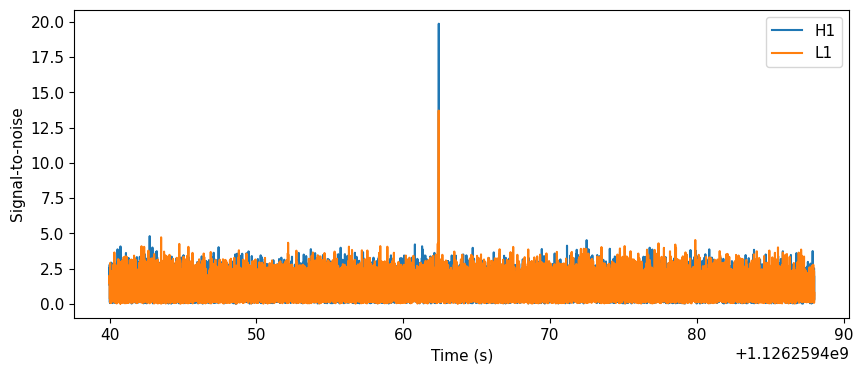

In [9]:
# Why are we taking an abs() here?
# The `matched_filter` function actually returns a 'complex' SNR.
# What that means is that the real portion corresponds to the SNR
# associated with directly filtering the template with the data.
# The imaginary portion corresponds to filtering with a template that
# is 90 degrees out of phase. Since the phase of a signal may be
# anything, we choose to maximize over the phase of the signal.

plt.figure(figsize=[10, 4])

for ifo in ifos:
    plt.plot(snr[ifo].sample_times, abs(snr[ifo]), label = ifo)
plt.ylabel('Signal-to-noise')
plt.xlabel('Time (s)')
plt.legend()
plt.show()


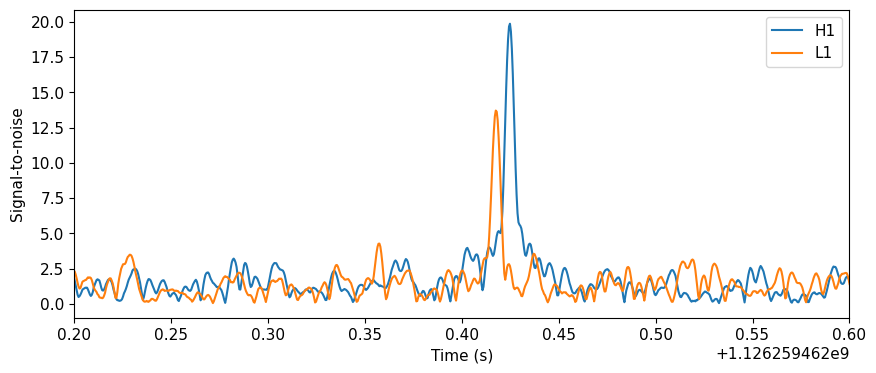

In [10]:
plt.figure(figsize=[10, 4])

for ifo in ifos:
    plt.plot(snr[ifo].sample_times, abs(snr[ifo]), label = ifo)
plt.ylabel('Signal-to-noise')
plt.xlabel('Time (s)')
plt.xlim(GPS-0.2, GPS+0.2)
plt.legend()
plt.show()

In [11]:
# trigger time and SNR in individual detectors.
snrp = {}
time = {}
network_snr = 0
for ifo in ifos:
    peak = abs(snr[ifo]).numpy().argmax()
    snrp[ifo] = snr[ifo][peak]
    time[ifo] = snr[ifo].sample_times[peak]
    network_snr += abs(snrp[ifo])**2

    print(f"We found a signal at {time[ifo]}s with SNR {abs(snrp[ifo])}")

network_snr = np.sqrt(network_snr)
print(f"Network SNR = {network_snr}")

We found a signal at 1126259462.4248047s with SNR 19.869037693798337
We found a signal at 1126259462.4174805s with SNR 13.706166387933996
Network SNR = 24.137888390066575


## What if we use different templates?

In [12]:
# template 2
m1, m2 = 29, 29
hp2, _ = get_td_waveform(approximant="SEOBNRv4",
                     mass1=m1,
                     mass2=m2,
                     delta_t=strain['H1'].delta_t,
                     f_lower=20)

# Resize the vector to match our data
hp2.resize(len(strain['H1']))
template2 = hp2.cyclic_time_shift(hp2.start_time)

# template 3
m1, m2 = 30, 25
hp3, _ = get_td_waveform(approximant="SEOBNRv4",
                     mass1=m1,
                     mass2=m2,
                     delta_t=strain['H1'].delta_t,
                     f_lower=20)

# Resize the vector to match our data
hp3.resize(len(strain['H1']))
template3 = hp3.cyclic_time_shift(hp3.start_time)

In [13]:
snr2 = {}
snr3 = {}
for ifo in ifos:
    snr2[ifo] = matched_filter(template2, strain[ifo],
                             psd=psds[ifo], low_frequency_cutoff=20)

    snr2[ifo] = snr2[ifo].crop(4 + 4, 4)

    snr3[ifo] = matched_filter(template3, strain[ifo],
                                 psd=psds[ifo], low_frequency_cutoff=20)
    
    snr3[ifo] = snr3[ifo].crop(4 + 4, 4)


In [14]:
snrp2 = {}
time2 = {}
network_snr2 = 0

for ifo in ifos:
    peak = abs(snr2[ifo]).numpy().argmax()
    snrp2[ifo] = snr2[ifo][peak]
    time2[ifo] = snr2[ifo].sample_times[peak]
    network_snr2 += abs(snrp2[ifo])**2

    print(f"We found a signal at {time2[ifo]}s with SNR {abs(snrp2[ifo])} with template 2.")

network_snr2 = np.sqrt(network_snr2)
print(f"Network SNR (template 2) = {network_snr2}")

We found a signal at 1126259462.4282227s with SNR 16.0868914982701 with template 2.
We found a signal at 1126259462.4208984s with SNR 11.293956592511437 with template 2.
Network SNR (template 2) = 19.655572583637632


In [15]:
snrp3 = {}
time3 = {}
network_snr3 = 0

for ifo in ifos:
    peak = abs(snr3[ifo]).numpy().argmax()
    snrp3[ifo] = snr3[ifo][peak]
    time3[ifo] = snr3[ifo].sample_times[peak]
    network_snr3 += abs(snrp3[ifo])**2

    print(f"We found a signal at {time3[ifo]}s with SNR {abs(snrp3[ifo])} with template 2.")

network_snr3 = np.sqrt(network_snr3)
print(f"Network SNR (template 2) = {network_snr3}")

We found a signal at 1126259462.428711s with SNR 13.850865251653799 with template 2.
We found a signal at 1126259462.4213867s with SNR 9.602496159088686 with template 2.
Network SNR (template 2) = 16.853913513032623


## Allen $\chi^2$: is SNR spread across frequency as expected?

Transient glitches can produce high SNRs.

Divide the template's expected noise-weighted power into $p$ frequency bands. Compare each band's measured contribution with what a consistent signal predicts. A commonly used reduced statistic is
$$\chi_r^2=\frac{\chi^2}{2p-2},$$
$$
\chi^2 = \sum^p_{i=0} (\rho_i - \rho / p)^2.
$$
$\chi_r^2=1$ is broadly consistent with the assumed model, though the precise behavior depends on the data and signal. A glitch can have high SNR but large $\chi_r^2$.


In [16]:
chisq = {}
for ifo in ifos:
    # The number of bins to use. In principle, this choice is arbitrary. In practice,
    # this is empirically tuned.
    nbins = 26
    chisq[ifo] = power_chisq(template, strain[ifo], nbins, psds[ifo], low_frequency_cutoff=20.0)
    chisq[ifo] = chisq[ifo].crop(8, 4)
    
    dof = nbins * 2 - 2
    chisq[ifo] /= dof

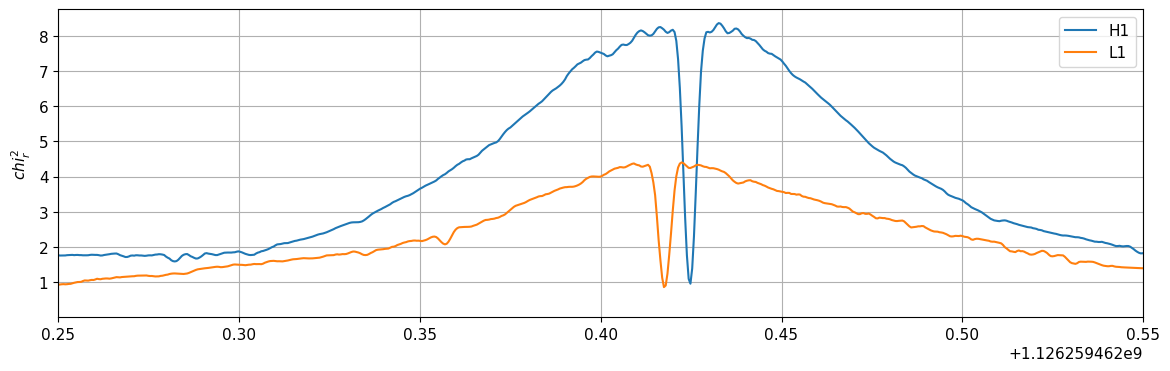

In [17]:
plt.figure(figsize=[14, 4])

for ifo in ifos:
    plt.plot(chisq[ifo].sample_times, chisq[ifo], label=ifo)
    
plt.legend()
plt.grid()
plt.xlim(GPS -0.15, GPS + 0.15)
# plt.ylim(0, 5)
plt.ylabel('$chi^2_r$')
plt.show()

## Reweighting: suppress high-$\chi^2$ triggers
PyCBC's `newsnr` uses the standard illustrative transformation
$$\hat\rho=\begin{cases}\rho,&\chi_r^2\leq1,\\\rho\left[\frac{1+(\chi_r^2)^3}{2}\right]^{-1/6},&\chi_r^2>1.\end{cases}$$
This is a **single-detector ranking ingredient**, not a detection significance or universal likelihood ratio.

**Exercise:** change $p$ from 16 to 8 or 32. Why might a very short-duration template have limited frequency bins?

**Takeaway:** high matched-filter SNR is interesting, but a physically consistent signal should also have the expected distribution of SNR across frequency.

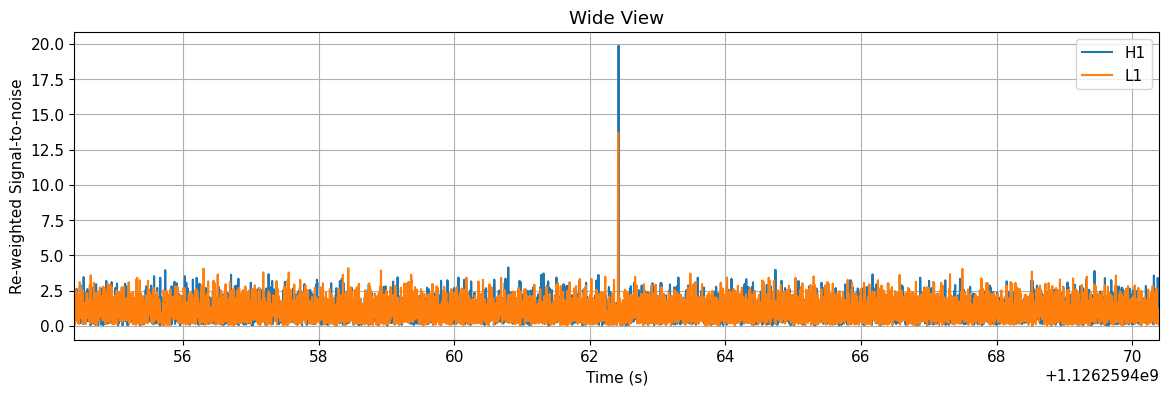

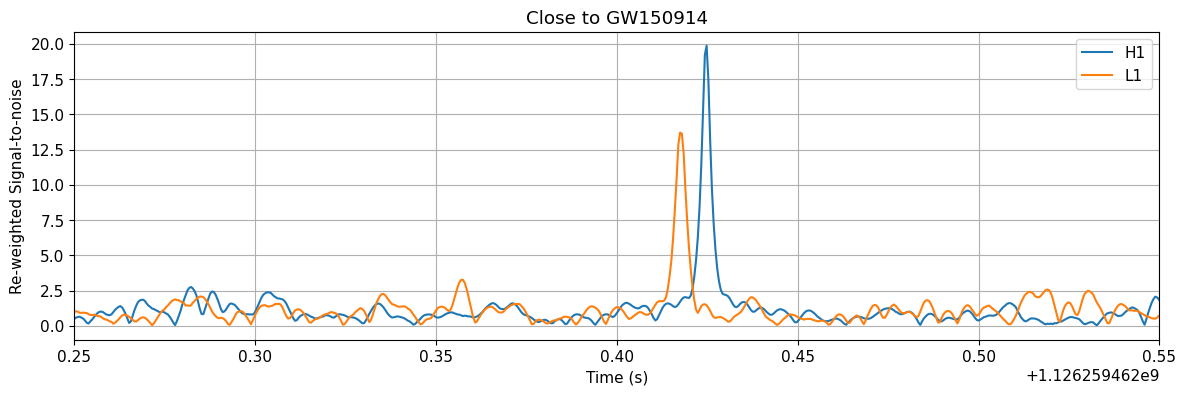

In [18]:
# The rho-hat term above is named "newsnr" here
rwtd_snr = {ifo:newsnr(abs(snr[ifo]), chisq[ifo]) for ifo in ifos}

# Show a couple sizes
for w, title in [(8, 'Wide View'), (.15, 'Close to GW150914')]:
    plt.figure(figsize=[14, 4])
    for ifo in ifos:
        plt.plot(snr[ifo].sample_times, rwtd_snr[ifo], label=ifo)

    plt.legend()
    plt.title(title)
    plt.grid()
    plt.xlim(GPS - w, GPS + w)
    # plt.ylim(0, 15)
    plt.xlabel('Time (s)')
    plt.ylabel('Re-weighted Signal-to-noise')
    plt.show()
    

## Exercise: Can an instrumental glitch produce a high matched-filter SNR?

A matched filter measures similarity to a template, so a short **non-astrophysical transient** can sometimes generate a high SNR. The Allen $\chi^2$ test checks *how the matched-filter output is distributed among frequency bands*, rather than relying on the total SNR alone.

We will inject a **synthetic sine-Gaussian glitch** into a **copy** of the H1 data, well away from GW150914:

$$g(t)=A\,\exp\!\left[-\frac{(t-t_g)^2}{2\sigma^2}\right]\sin\left[2\pi f_0(t-t_g)\right].$$

To compare SNR and $\chi_r^2$ fairly, we reuse the **same template and original noise PSD**, without allowing the injected transient to bias the PSD estimate. We scale the glitch amplitude to produce an easily visible SNR peak. The $\chi_r^2$ value is **not preset**; it is determined by the mismatch between the glitch and the template.

> This is an illustrative consistency check, not a full glitch-veto study. Some glitches can pass the $\chi^2$ test, and genuinely astrophysical signals can have elevated $\chi^2$ with an inaccurate template or nonstationary noise.

In [66]:
# Inject a synthetic sine-Gaussian glitch into a COPY of the H1 strain.

ifo = 'H1'
data_original = strain[ifo]
psd_fixed = psds[ifo]

glitch_time = GPS + 7.0      # away from GW150914
glitch_frequency = 100.0     # Hz
glitch_sigma = 0.015         # seconds (Gaussian width)
target_glitch_snr = 25.0     # approximate matched-filter SNR from glitch alone

relative_t = np.asarray(data_original.sample_times) - glitch_time
unit_glitch = np.exp(-0.5 * (relative_t / glitch_sigma)**2) * np.sin(2 * np.pi * glitch_frequency * relative_t)

# Calibrate the amplitude by filtering the glitch alone with the SAME PSD.
# A strain amplitude of 1 is arbitrary, so this determines an appropriate scale.

# convert to PyCBC TimeSeries
glitch_unit_ts = TimeSeries(unit_glitch, delta_t=data_original.delta_t, epoch=data_original.start_time)
unit_snr_ts = matched_filter(template, glitch_unit_ts, psd=psd_fixed, low_frequency_cutoff=20).crop(8, 4)

unit_times = np.asarray(unit_snr_ts.sample_times)
unit_near = np.abs(unit_times - glitch_time) < 1.5
unit_response = np.max(np.abs(np.asarray(unit_snr_ts)[unit_near]))
if unit_response == 0:
    raise ValueError('Glitch did not overlap the valid matched-filter interval.')

amplitude = target_glitch_snr / unit_response
glitch = amplitude * unit_glitch

data_glitch = data_original.copy()
data_glitch.data[:] += glitch  # original data are unchanged



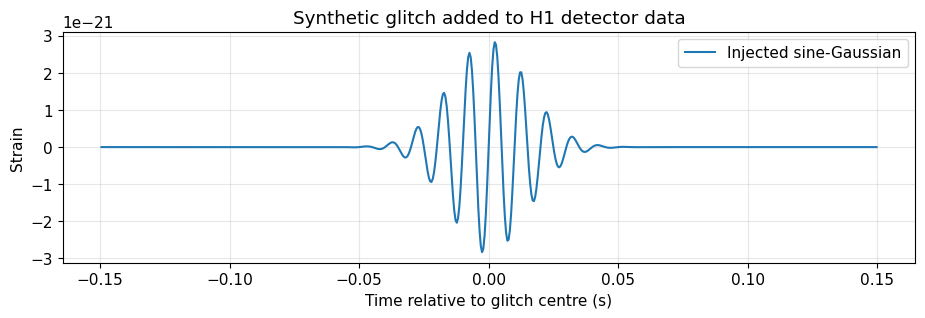

In [67]:
fig, ax = plt.subplots(figsize=(11, 3))
plot_mask = np.abs(relative_t) < 0.15
ax.plot(relative_t[plot_mask], glitch[plot_mask], label='Injected sine-Gaussian')
ax.set(xlabel='Time relative to glitch centre (s)', ylabel='Strain',
       title='Synthetic glitch added to H1 detector data')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [68]:
# Run exactly the same matched-filter, Allen chi-square and reweighting operations
glitch_snr_ts = matched_filter(template, data_glitch, psd=psd_fixed,
                               low_frequency_cutoff=20).crop(8, 4)

nbins = 26
glitch_chisq_ts = power_chisq(template, data_glitch, nbins, psd_fixed,
                              low_frequency_cutoff=20).crop(8, 4)

glitch_chisq_ts /= 2 * nbins - 2 

glitch_reweighted = newsnr(np.abs(glitch_snr_ts), glitch_chisq_ts)

# Identify the SNR peak close to the glitch.
snr_times = np.asarray(glitch_snr_ts.sample_times)
near_glitch = np.flatnonzero(np.abs(snr_times - glitch_time) < 1.5)
peak_idx = near_glitch[np.argmax(np.abs(np.asarray(glitch_snr_ts)[near_glitch]))]
glitch_peak_time = float(snr_times[peak_idx])

# For comparison, evaluate the original GW150914 trigger with the same template.
# Use a local window, since the global maximum need not be at GW150914.
orig_times = np.asarray(snr[ifo].sample_times)
near_gw = np.flatnonzero(np.abs(orig_times - GPS) < 0.2)
gw_peak_idx = near_gw[np.argmax(np.abs(np.asarray(snr[ifo])[near_gw]))]

print('                     SNR       Reduced chi-square    Reweighted SNR')
print(f'GW150914 (H1)     {abs(snr[ifo][gw_peak_idx]):8.2f} '
      f'{float(chisq[ifo][gw_peak_idx]):16.2f} '
      f'{float(newsnr(abs(snr[ifo][gw_peak_idx]), chisq[ifo][gw_peak_idx])):17.2f}')
print(f'Synthetic glitch  {abs(glitch_snr_ts[peak_idx]):8.2f} '
      f'{float(glitch_chisq_ts[peak_idx]):16.2f} '
      f'{float(glitch_reweighted[peak_idx]):17.2f}')
print(f'Glitch centre: {glitch_time:.3f}; matched-filter peak: {glitch_peak_time:.3f}')


                     SNR       Reduced chi-square    Reweighted SNR
GW150914 (H1)        19.87             0.96             19.87
Synthetic glitch     26.38            48.04              4.27
Glitch centre: 1126259469.400; matched-filter peak: 1126259469.407


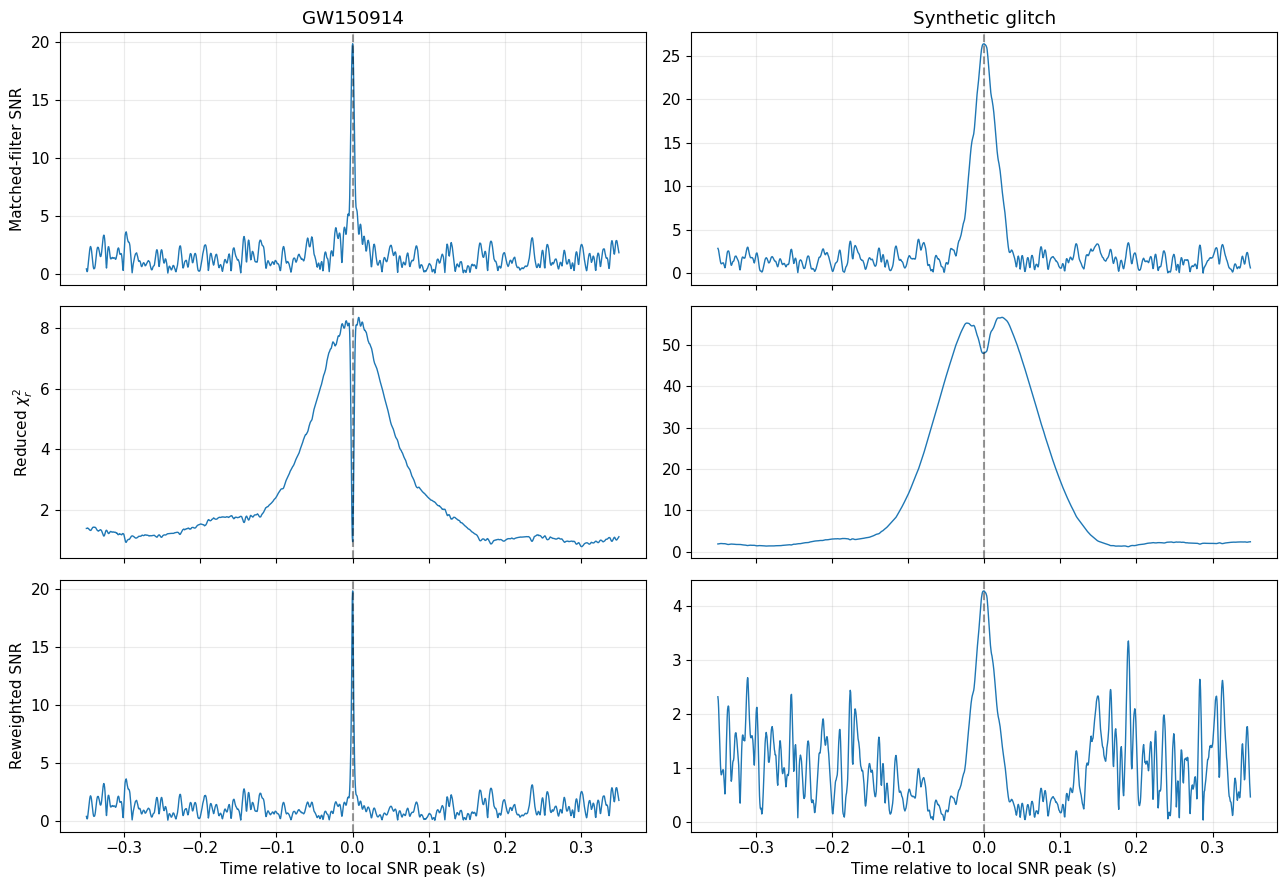

In [70]:
# Plot all three ranking quantities around GW150914 and the injected glitch.
fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex='col')

comparisons = [
    ('GW150914', float(orig_times[gw_peak_idx]),
     np.asarray(snr[ifo].sample_times), np.abs(np.asarray(snr[ifo])),
     np.asarray(chisq[ifo]), np.asarray(newsnr(abs(snr[ifo]), chisq[ifo]))),
    ('Synthetic glitch', glitch_peak_time,
     snr_times, np.abs(np.asarray(glitch_snr_ts)),
     np.asarray(glitch_chisq_ts), np.asarray(glitch_reweighted))
]
for col, (title, centre, times, rho, chi2r, rhohat) in enumerate(comparisons):
    mask = np.abs(times - centre) < 0.35
    x = times[mask] - centre
    for row, (vals, label) in enumerate([(rho, 'Matched-filter SNR'),
                                         (chi2r, r'Reduced $\chi^2_r$'),
                                         (rhohat, 'Reweighted SNR')]):

        axes[row, col].plot(x, vals[mask], lw=1)
        axes[row, col].axvline(0, color='k', ls='--', alpha=0.4)
        axes[row, col].grid(alpha=0.25)
        if col == 0:
            axes[row, col].set_ylabel(label)
            
    axes[0, col].set_title(title)
    axes[-1, col].set_xlabel('Time relative to local SNR peak (s)')

plt.tight_layout()
plt.show()


**Questions**

1. Did the artificial glitch produce a high matched-filter SNR despite not being a compact-binary waveform?
2. Compare $\chi_r^2$ **at the SNR peak** (rather than its maximum elsewhere). Does the glitch distribute its energy across the frequency bands as expected for the template?
3. Compare the reweighted SNRs. Did the consistency test reduce the ranking of the glitch?
4. Try changing `glitch_frequency` (e.g. 70 or 150 Hz) and `glitch_sigma` (e.g. 0.008 or 0.03 s). Are *all* glitches strongly rejected? Why might additional signal-consistency tests be useful?
